In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd

caradje_march = pd.read_csv(
    "/content/drive/MyDrive/Caradje_CEME/caradje_march_clean.csv",
    index_col=0,
)
caradje_march["origin_datetime"] = pd.to_datetime(
    caradje_march["origin_datetime"], utc=True, format="mixed"
)

In [5]:

# Install ObsPy
!pip -q install obspy

# Import ObsPy
from obspy import read

# Read three-component seismic waveforms
st = read("/content/drive/MyDrive/Caradje_CEME/ME.CEME..HH?.D.2024.074")

# Display waveform information
print(st)


3 Trace(s) in Stream:
ME.CEME..HHE | 2024-03-14T00:00:04.380000Z - 2024-03-15T00:00:01.920000Z | 100.0 Hz, 8639755 samples
ME.CEME..HHN | 2024-03-14T00:00:05.710000Z - 2024-03-15T00:00:04.150000Z | 100.0 Hz, 8639845 samples
ME.CEME..HHZ | 2024-03-14T00:00:02.180000Z - 2024-03-15T00:00:01.130000Z | 100.0 Hz, 8639896 samples


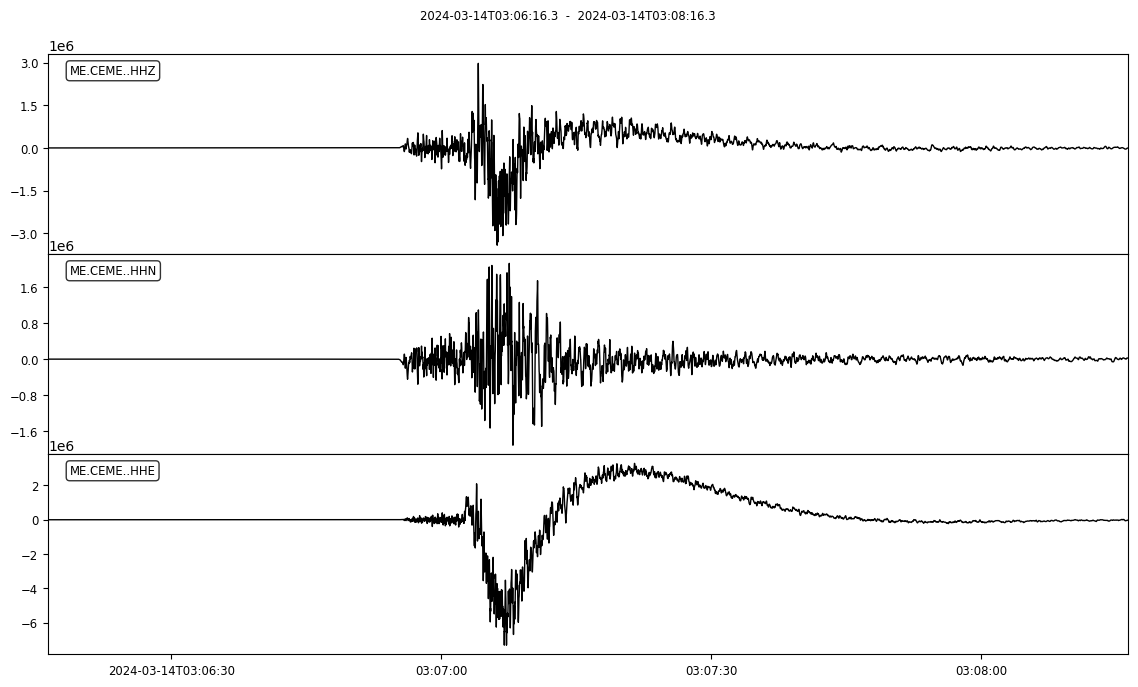

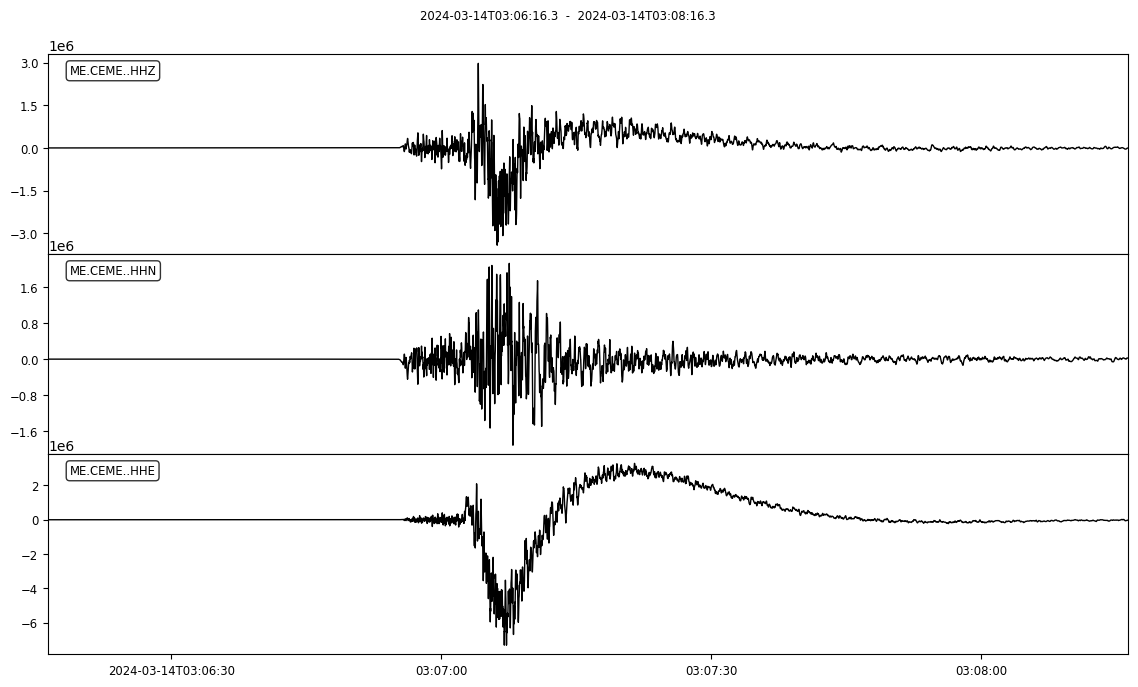

In [6]:

from obspy import UTCDateTime

# Mainshock origin time
t0 = UTCDateTime("2024-03-14T03:06:46.300")

# Extract a two-minute window around the mainshock
st_event = st.copy().trim(
    starttime=t0 - 30,
    endtime=t0 + 90
)

# Display three-component waveforms
st_event.plot(
    size=(1200, 700),
    equal_scale=False
)


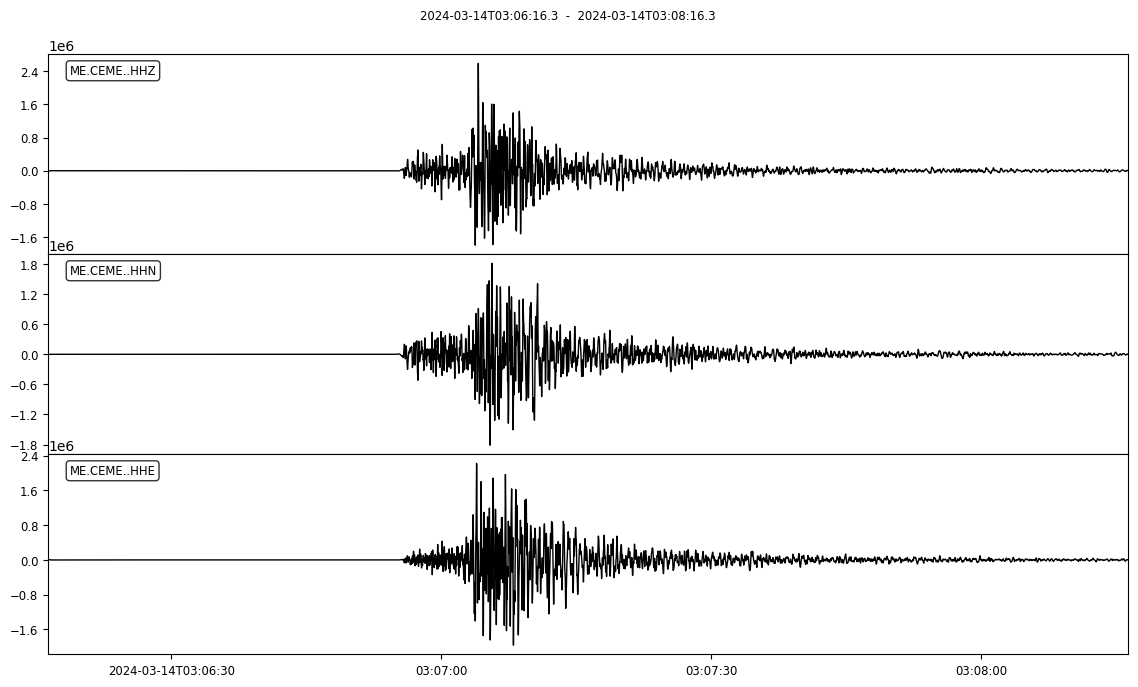

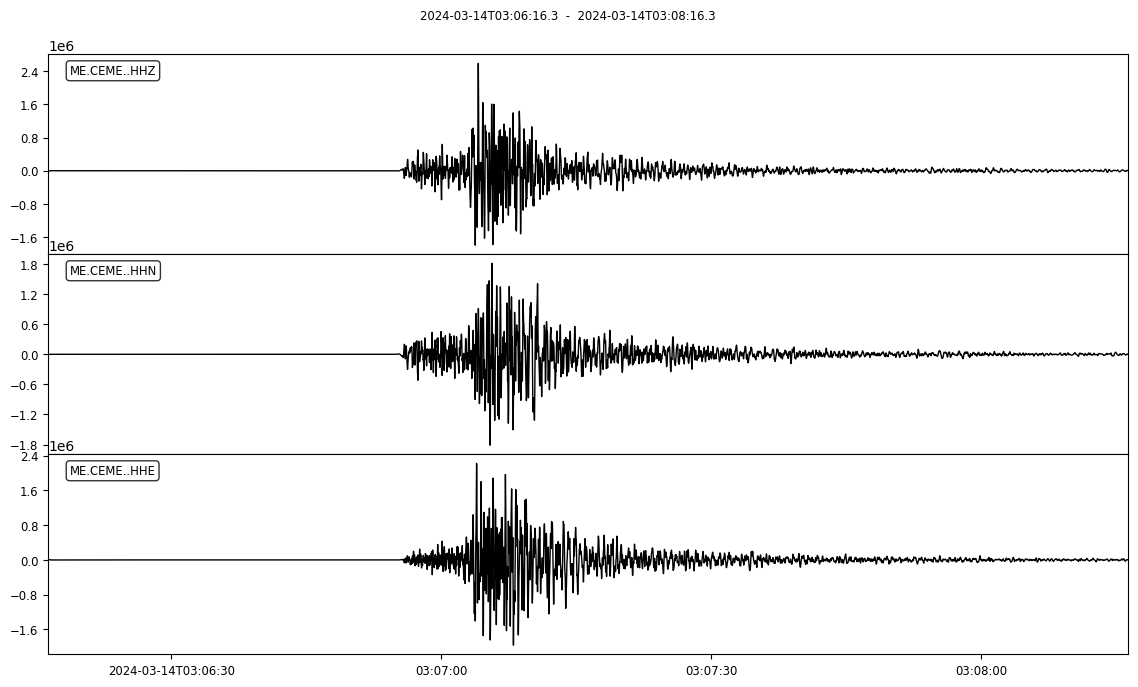

In [7]:

# Create a copy of the original waveforms
st_filtered = st_event.copy()

# Remove mean and linear trend
st_filtered.detrend("demean")
st_filtered.detrend("linear")

# Apply a bandpass filter
st_filtered.filter(
    "bandpass",
    freqmin=1.0,
    freqmax=15.0,
    corners=4,
    zerophase=True
)

# Plot filtered three-component waveforms
st_filtered.plot(
    size=(1200, 700),
    equal_scale=False
)



### Preliminary P- and S-Wave Arrival Detection — CEME

**Objective:** Develop a custom time series approach for identifying P- and S-wave onsets without pretrained models.

**Data:** 14 March 2024, Čarađe M5.3 earthquake; CEME station; 100 Hz MiniSEED waveforms.

#### P-wave detection (HHZ)
- Calculated absolute amplitude differences using `.diff()`.
- Estimated background noise over a 3.5-second window.
- Applied a robust threshold based on median and MAD.
- Selected the first threshold crossing as the P-arrival candidate.





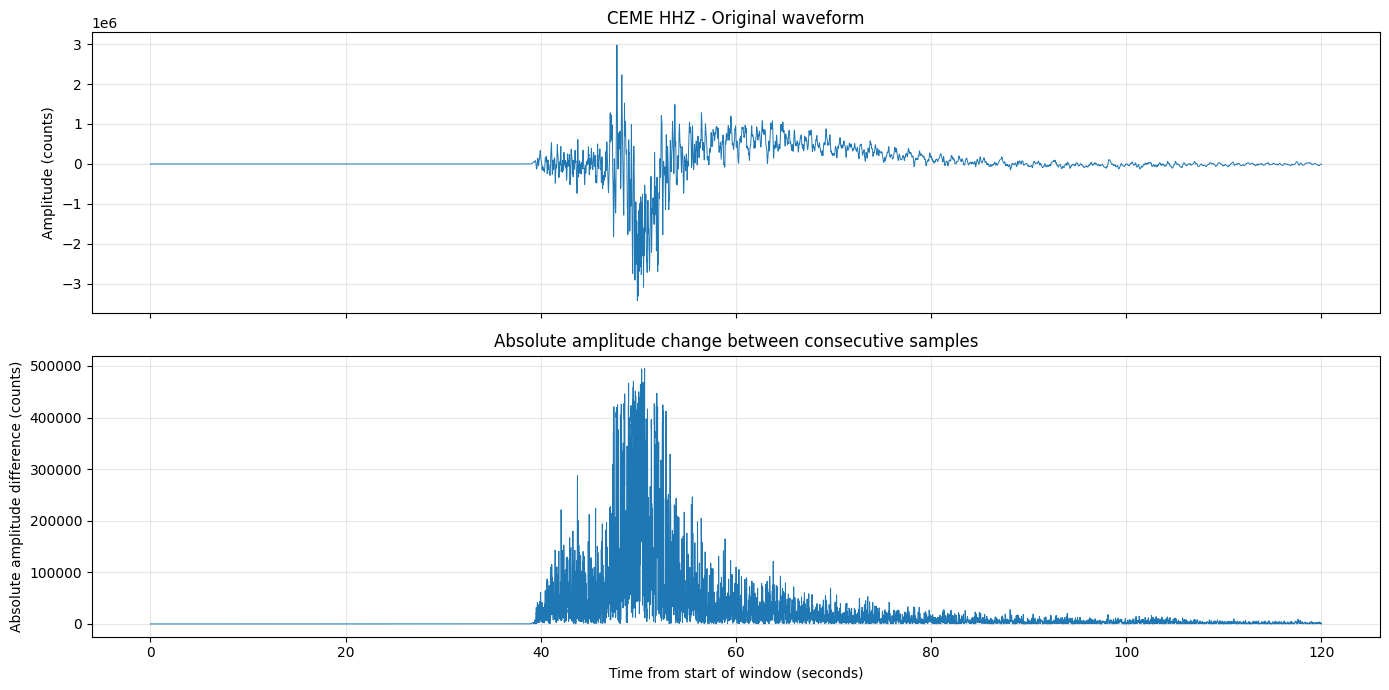

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the vertical component of the mainshock waveform
tr = st_event.select(channel="HHZ")[0].copy()

# Create a time series with amplitude values
time = tr.times()
amplitude = pd.Series(tr.data.astype(float))

# Calculate amplitude changes between consecutive samples
amplitude_diff = amplitude.diff().abs().fillna(0)

# Plot the original signal and amplitude changes
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time, amplitude, linewidth=0.7)
axes[0].set_title("CEME HHZ - Original waveform")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].grid(alpha=0.3)

axes[1].plot(time, amplitude_diff, linewidth=0.7)
axes[1].set_title("Absolute amplitude change between consecutive samples")
axes[1].set_xlabel("Time from start of window (seconds)")
axes[1].set_ylabel("Absolute amplitude difference (counts)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


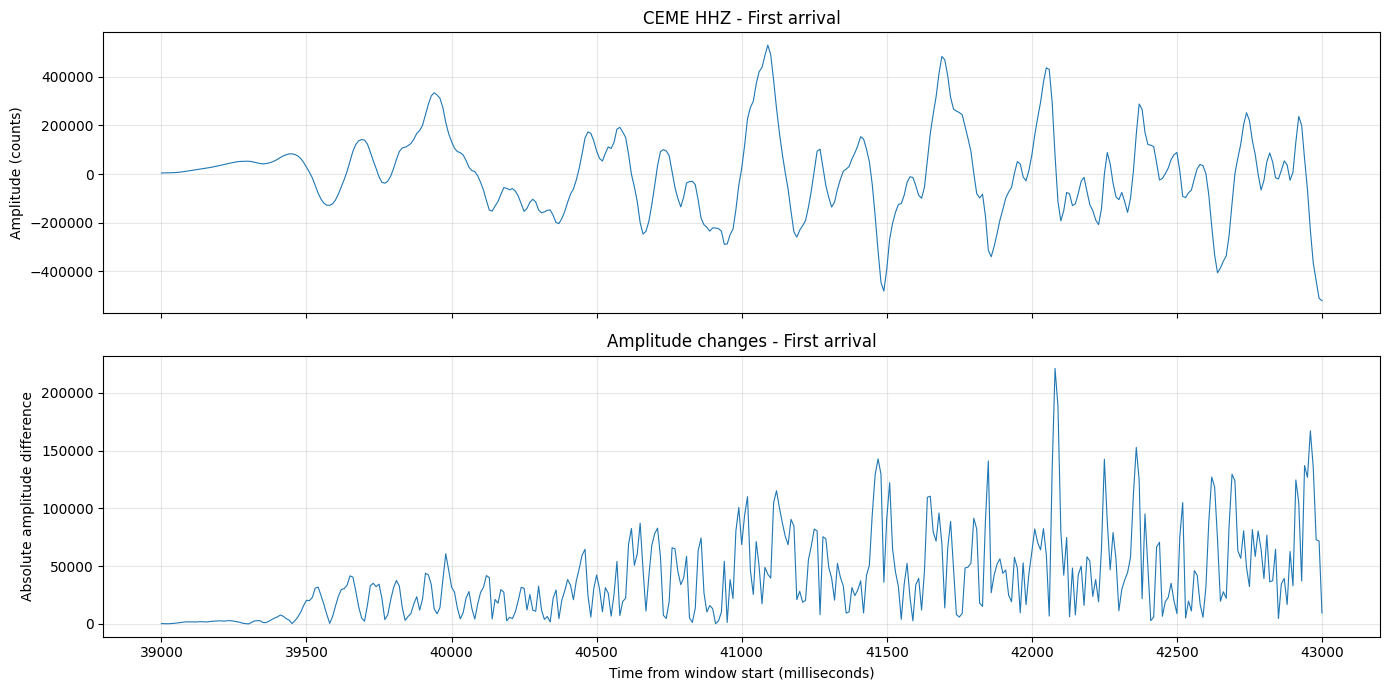

In [9]:

# Zoom into the beginning of the seismic signal
time_ms = time * 1000

# Select the interval from 39 to 43 seconds
mask = (time_ms >= 39000) & (time_ms <= 43000)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time_ms[mask], amplitude[mask], linewidth=0.8)
axes[0].set_title("CEME HHZ - First arrival")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].grid(alpha=0.3)

axes[1].plot(time_ms[mask], amplitude_diff[mask], linewidth=0.8)
axes[1].set_title("Amplitude changes - First arrival")
axes[1].set_xlabel("Time from window start (milliseconds)")
axes[1].set_ylabel("Absolute amplitude difference")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


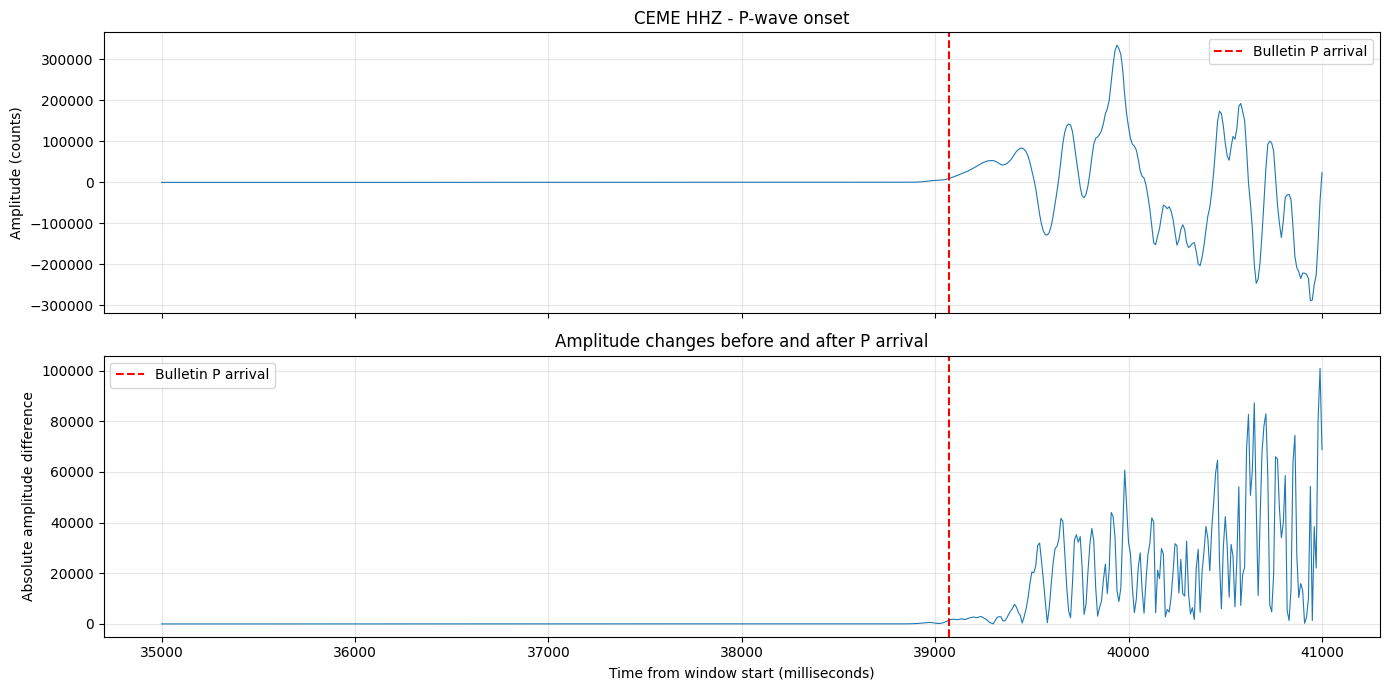

In [10]:

# Reference P arrival from the seismic bulletin
p_reference = 39070  # milliseconds from waveform start

# Select 35–41 seconds of the waveform
mask = (time_ms >= 35000) & (time_ms <= 41000)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Original waveform
axes[0].plot(time_ms[mask], amplitude[mask], linewidth=0.8)
axes[0].axvline(p_reference, color="red", linestyle="--",
                label="Bulletin P arrival")
axes[0].set_title("CEME HHZ - P-wave onset")
axes[0].set_ylabel("Amplitude (counts)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Amplitude differences
axes[1].plot(time_ms[mask], amplitude_diff[mask], linewidth=0.8)
axes[1].axvline(p_reference, color="red", linestyle="--",
                label="Bulletin P arrival")
axes[1].set_title("Amplitude changes before and after P arrival")
axes[1].set_xlabel("Time from window start (milliseconds)")
axes[1].set_ylabel("Absolute amplitude difference")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Detected P arrival: 38820 ms
Bulletin P arrival: 39070 ms
Difference: -250 ms


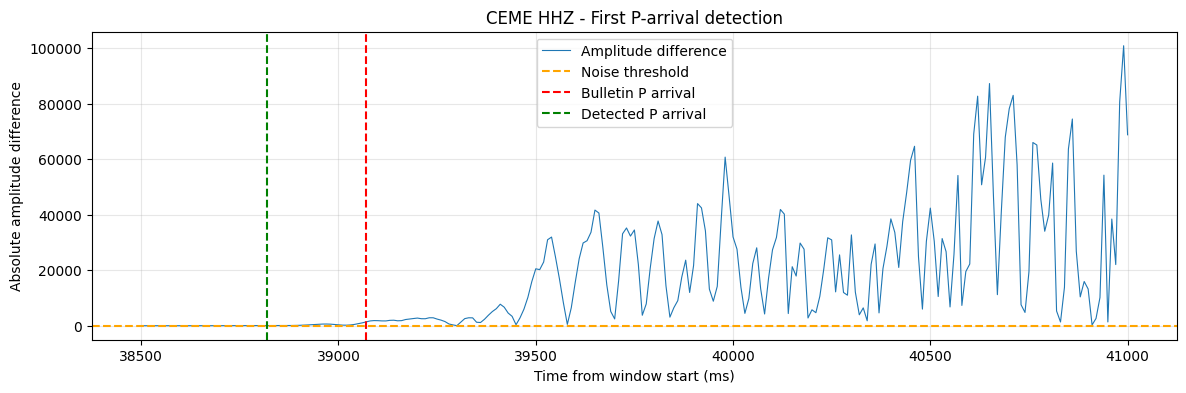

In [11]:

# Estimate background noise before the P arrival
noise_mask = (time_ms >= 35000) & (time_ms < 38500)

noise = amplitude_diff[noise_mask]

# Robust threshold using median and MAD
median_noise = np.median(noise)
mad_noise = np.median(np.abs(noise - median_noise))

threshold = median_noise + 6 * 1.4826 * mad_noise

# Search for the first significant amplitude change
search_mask = (time_ms >= 38500) & (time_ms <= 41000)

candidate_indices = np.where(
    search_mask & (amplitude_diff.to_numpy() > threshold)
)[0]

if len(candidate_indices) > 0:
    p_index = candidate_indices[0]
    p_time_ms = time_ms[p_index]

    print(f"Detected P arrival: {p_time_ms:.0f} ms")
    print(f"Bulletin P arrival: {p_reference:.0f} ms")
    print(f"Difference: {p_time_ms - p_reference:.0f} ms")
else:
    p_time_ms = None
    print("No P arrival detected.")

# Plot the detection threshold and reference arrival
plt.figure(figsize=(14, 4))
plt.plot(time_ms[search_mask], amplitude_diff[search_mask],
         linewidth=0.8, label="Amplitude difference")
plt.axhline(threshold, color="orange", linestyle="--",
            label="Noise threshold")
plt.axvline(p_reference, color="red", linestyle="--",
            label="Bulletin P arrival")

if p_time_ms is not None:
    plt.axvline(p_time_ms, color="green", linestyle="--",
                label="Detected P arrival")

plt.xlabel("Time from window start (ms)")
plt.ylabel("Absolute amplitude difference")
plt.title("CEME HHZ - First P-arrival detection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [12]:

# Convert detected arrival to absolute UTC time
p_arrival_utc = tr.stats.starttime + p_time_ms / 1000

print(f"Detected P arrival (UTC): {p_arrival_utc}")


Detected P arrival (UTC): 2024-03-14T03:06:55.120000Z


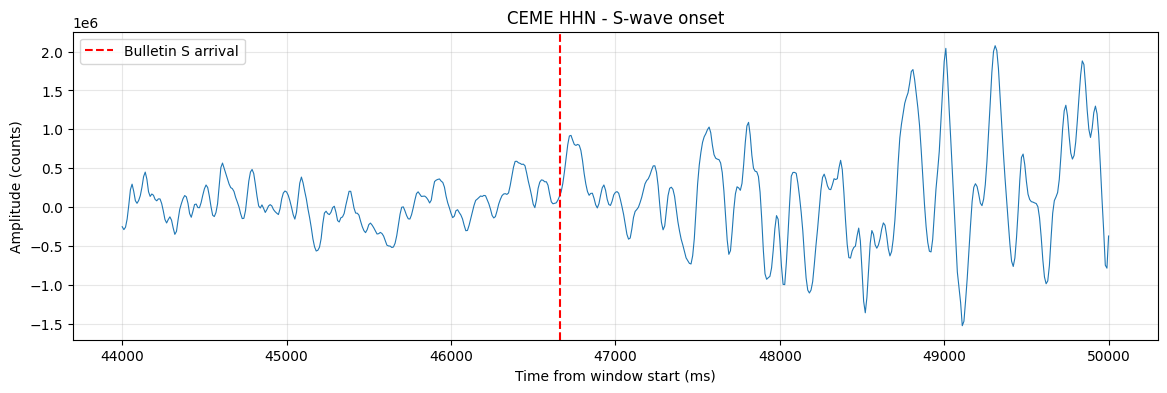

In [14]:

# Select HHN component for S-wave analysis
tr_n = st_event.select(channel="HHN")[0]

time_ms = tr_n.times() * 1000
s_reference = 46660  # Bulletin S arrival in milliseconds

mask = (time_ms >= 44000) & (time_ms <= 50000)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], tr_n.data[mask], linewidth=0.8)
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

plt.title("CEME HHN - S-wave onset")
plt.xlabel("Time from window start (ms)")
plt.ylabel("Amplitude (counts)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


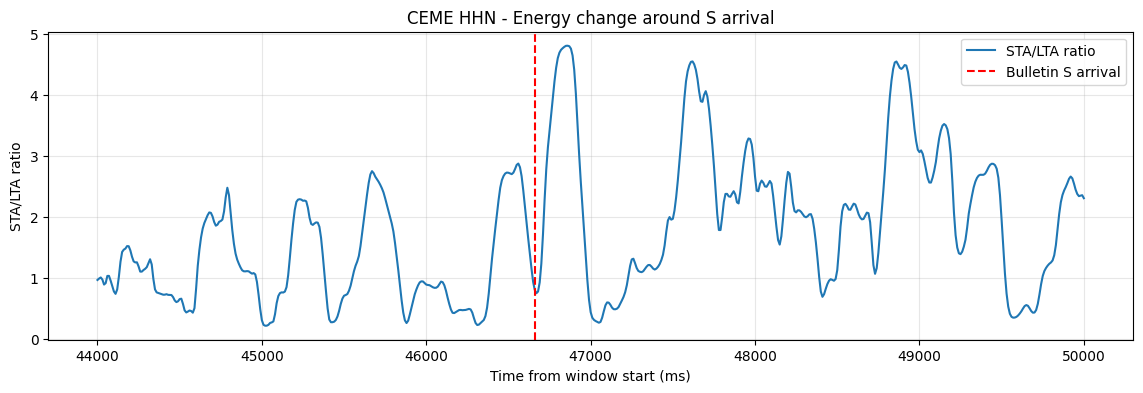

In [15]:

# Calculate signal energy on the HHN component
energy = pd.Series(tr_n.data.astype(float) ** 2)

# Sampling frequency
fs = tr_n.stats.sampling_rate

# Short and long moving averages
sta = energy.rolling(window=int(0.2 * fs), min_periods=1).mean()
lta = energy.rolling(window=int(3.0 * fs), min_periods=1).mean()

# STA/LTA ratio
ratio = sta / (lta + 1e-12)

# Display the interval around the S arrival
mask = (time_ms >= 44000) & (time_ms <= 50000)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], ratio[mask], label="STA/LTA ratio")
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

plt.xlabel("Time from window start (ms)")
plt.ylabel("STA/LTA ratio")
plt.title("CEME HHN - Energy change around S arrival")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


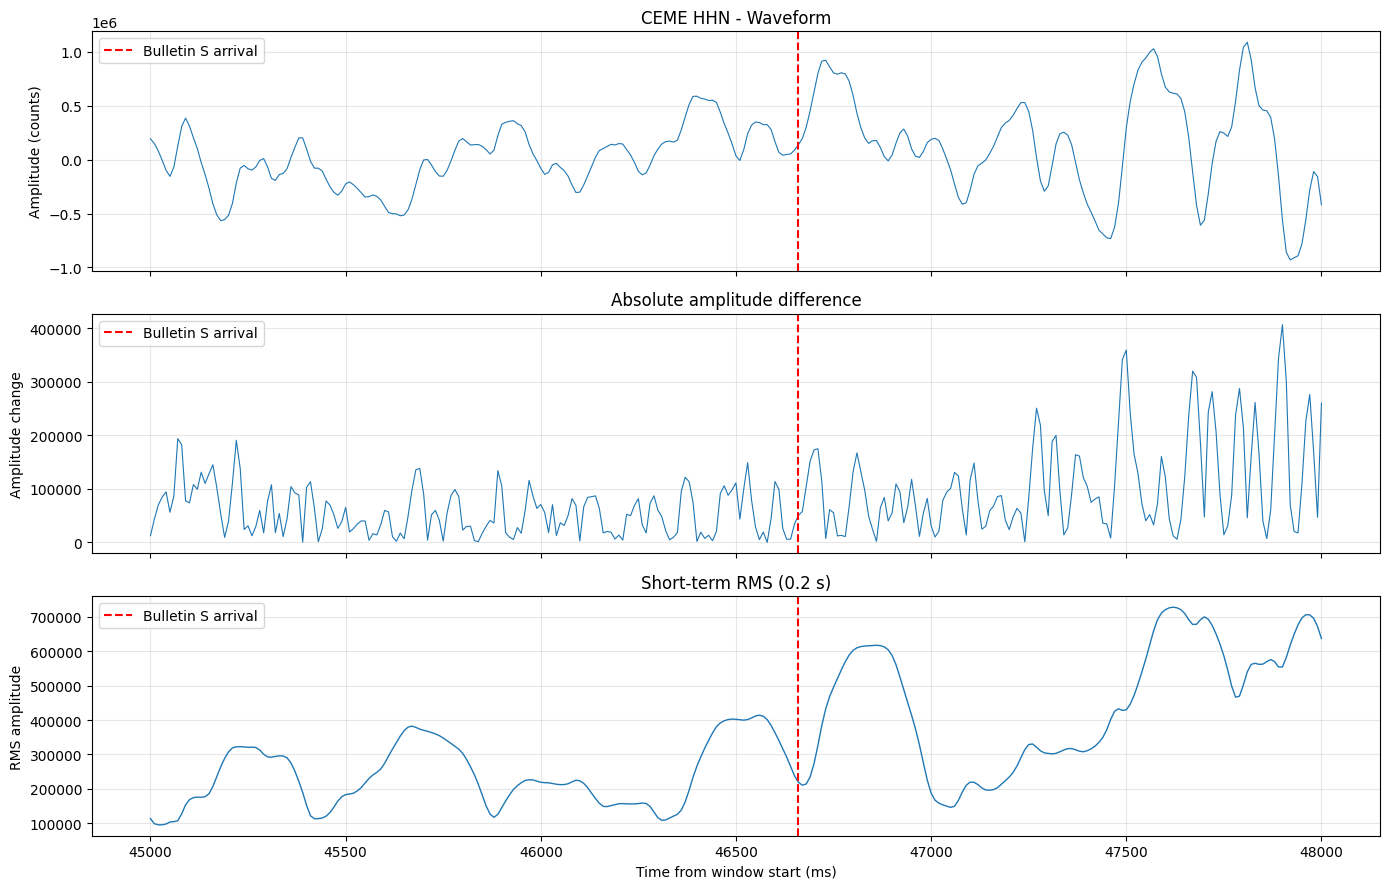

In [16]:

# HHN amplitude time series
hhn = pd.Series(tr_n.data.astype(float))

# Absolute amplitude change between samples
hhn_diff = hhn.diff().abs().fillna(0)

# Short-term RMS amplitude (0.2 seconds)
fs = tr_n.stats.sampling_rate
window = int(0.2 * fs)

hhn_rms = np.sqrt(
    (hhn ** 2).rolling(window=window, min_periods=window).mean()
)

# Focus on the S-wave arrival
mask = (time_ms >= 45000) & (time_ms <= 48000)

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(time_ms[mask], hhn[mask], linewidth=0.8)
axes[0].set_ylabel("Amplitude (counts)")
axes[0].set_title("CEME HHN - Waveform")

axes[1].plot(time_ms[mask], hhn_diff[mask], linewidth=0.8)
axes[1].set_ylabel("Amplitude change")
axes[1].set_title("Absolute amplitude difference")

axes[2].plot(time_ms[mask], hhn_rms[mask], linewidth=1)
axes[2].set_ylabel("RMS amplitude")
axes[2].set_title("Short-term RMS (0.2 s)")
axes[2].set_xlabel("Time from window start (ms)")

for ax in axes:
    ax.axvline(
        s_reference,
        color="red",
        linestyle="--",
        label="Bulletin S arrival"
    )
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


S candidate: 46830 ms
S candidate UTC: 2024-03-14T03:07:03.130000Z
Bulletin S: 46660 ms
Difference: 170 ms


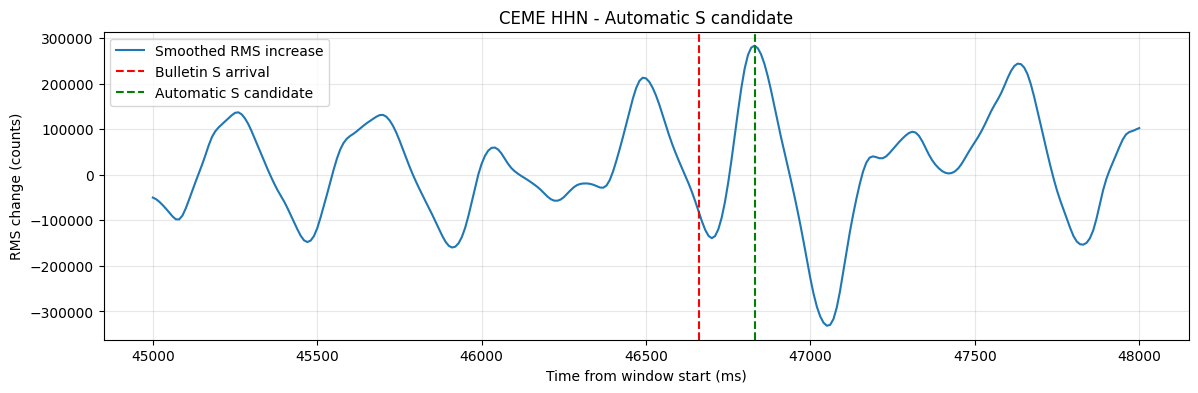

In [17]:

# Detect sustained RMS increase on the HHN component

rms_values = hhn_rms.to_numpy()
t = time_ms

# Calculate RMS change over 0.1 seconds
lag = int(0.1 * fs)
rms_change = hhn_rms.diff(periods=lag)

# Smooth the change over 0.1 seconds
smooth_change = rms_change.rolling(
    window=lag, min_periods=lag
).mean()

# Search for the strongest sustained RMS increase
# within the exploratory S-phase interval
search_mask = (t >= 45000) & (t <= 48000)

valid_indices = np.where(
    search_mask & np.isfinite(smooth_change.to_numpy())
)[0]

if len(valid_indices) > 0:
    s_index = valid_indices[
        np.argmax(smooth_change.iloc[valid_indices].to_numpy())
    ]

    s_candidate_ms = t[s_index]
    s_candidate_utc = tr_n.stats.starttime + s_candidate_ms / 1000

    print(f"S candidate: {s_candidate_ms:.0f} ms")
    print(f"S candidate UTC: {s_candidate_utc}")
    print(f"Bulletin S: {s_reference:.0f} ms")
    print(f"Difference: {s_candidate_ms - s_reference:.0f} ms")
else:
    s_candidate_ms = None
    print("No valid S candidate found.")

# Plot the RMS change
plt.figure(figsize=(14, 4))
plt.plot(t[search_mask], smooth_change[search_mask],
         label="Smoothed RMS increase")

plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")

if s_candidate_ms is not None:
    plt.axvline(s_candidate_ms, color="green", linestyle="--",
                label="Automatic S candidate")

plt.xlabel("Time from window start (ms)")
plt.ylabel("RMS change (counts)")
plt.title("CEME HHN - Automatic S candidate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Estimated S onset: 2024-03-14T03:07:02.970000Z
Difference from bulletin: 10 ms


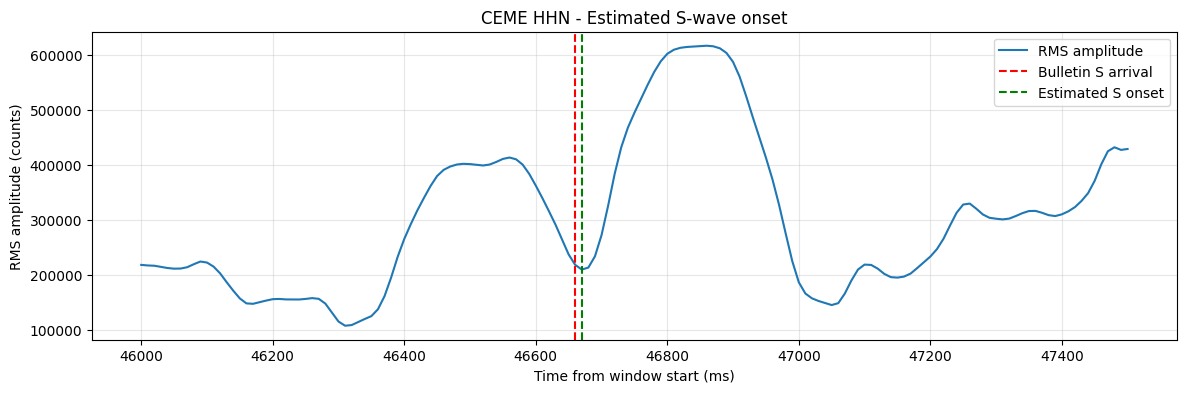

In [18]:

# Find the beginning of the RMS increase before the detected maximum

# Search up to 0.3 seconds before the RMS maximum
lookback = int(0.3 * fs)

start_idx = max(0, s_index - lookback)

# Find the local minimum of RMS before the maximum
rms_segment = hhn_rms.iloc[start_idx:s_index + 1]

s_onset_index = rms_segment.idxmin()
s_onset_ms = time_ms[s_onset_index]

# Convert to absolute UTC time
s_onset_utc = tr_n.stats.starttime + s_onset_ms / 1000

print(f"Estimated S onset: {s_onset_utc}")
print(f"Difference from bulletin: {(s_onset_ms - s_reference):.0f} ms")

# Plot the result
mask = (time_ms >= 46000) & (time_ms <= 47500)

plt.figure(figsize=(14, 4))
plt.plot(time_ms[mask], hhn_rms[mask], label="RMS amplitude")
plt.axvline(s_reference, color="red", linestyle="--",
            label="Bulletin S arrival")
plt.axvline(s_onset_ms, color="green", linestyle="--",
            label="Estimated S onset")
plt.xlabel("Time from window start (ms)")
plt.ylabel("RMS amplitude (counts)")
plt.title("CEME HHN - Estimated S-wave onset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Testing P- and S-Wave Detection on a Second Earthquake

We select a smaller aftershock (ML 3.2, March 14, 2024, 03:14:46 UTC) to evaluate our detection algorithms.

First, we extract and visualize the three-component CEME waveforms to inspect signal quality and possible overlapping events.

The goal is to test P- and S-wave arrival detection using the same algorithm parameters and compare the results with the manually picked phases in the seismic bulletin.


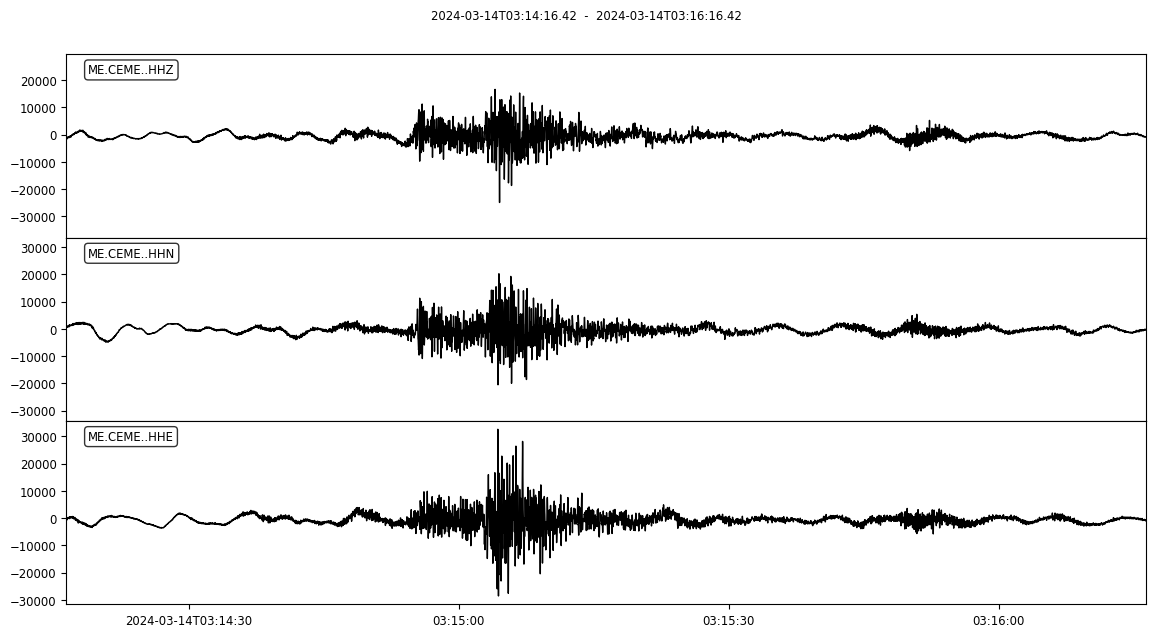

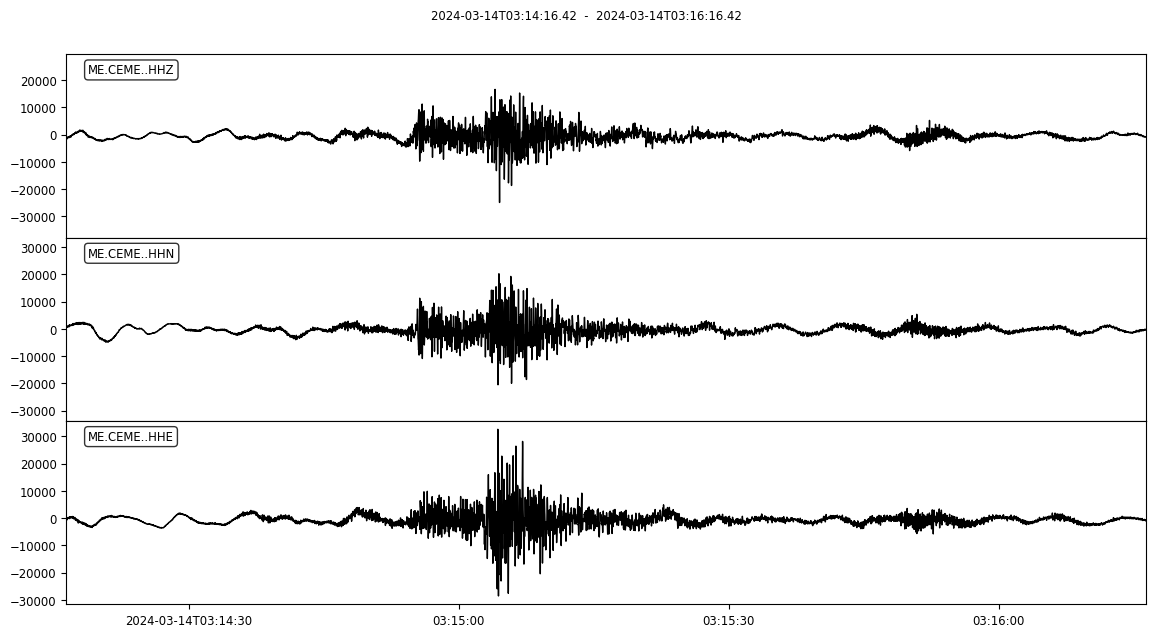

In [19]:

from obspy import UTCDateTime

# Second test event: ML 3.2
t0_test = UTCDateTime("2024-03-14T03:14:46.420")

# Extract waveform window
st_test = st.slice(
    starttime=t0_test - 30,
    endtime=t0_test + 90
).copy()

st_test.plot(size=(1200, 650))


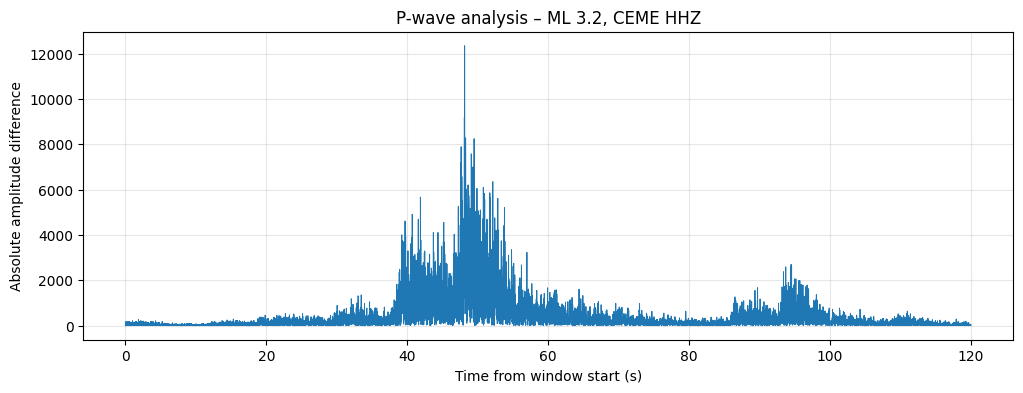

In [20]:

# P-wave analysis for the second earthquake (HHZ)

tr_test = st_test.select(channel="HHZ")[0].copy()

time_test = tr_test.times() * 1000
amplitude_test = pd.Series(tr_test.data.astype(float))
amplitude_diff_test = amplitude_test.diff().abs().fillna(0)

# Visualize amplitude changes
plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, amplitude_diff_test, linewidth=0.7)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave analysis – ML 3.2, CEME HHZ")
plt.grid(alpha=0.3)
plt.show()


In [21]:

# Same P-wave threshold method as for the mainshock

noise = amplitude_diff_test[
    (time_test >= 30000) & (time_test < 35000)
]

median_noise = noise.median()
mad_noise = (noise - median_noise).abs().median()

threshold = median_noise + 6 * 1.4826 * mad_noise

print("Threshold:", threshold)


Threshold: 1630.2136


In [22]:

# Detect the first threshold crossing after the noise window

search_mask = (time_test >= 35000) & (time_test <= 45000)

candidates = np.where(
    search_mask & (amplitude_diff_test.to_numpy() > threshold)
)[0]

if len(candidates) > 0:
    p_index_test = candidates[0]
    p_time_test = time_test[p_index_test]
    p_utc_test = tr_test.stats.starttime + p_time_test / 1000

    print("Detected P arrival:", p_utc_test)
else:
    print("No P arrival detected")


Detected P arrival: 2024-03-14T03:14:54.940000Z


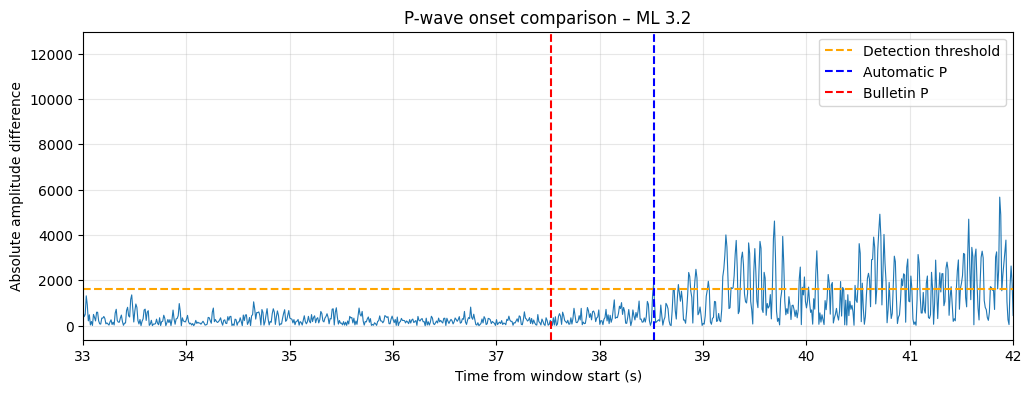

In [23]:

# Inspect the detected P-wave onset

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_diff_test, lw=0.8)

plt.axhline(threshold, color="orange",
            linestyle="--", label="Detection threshold")

plt.axvline(p_time_test / 1000, color="blue",
            linestyle="--", label="Automatic P")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(33, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave onset comparison – ML 3.2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


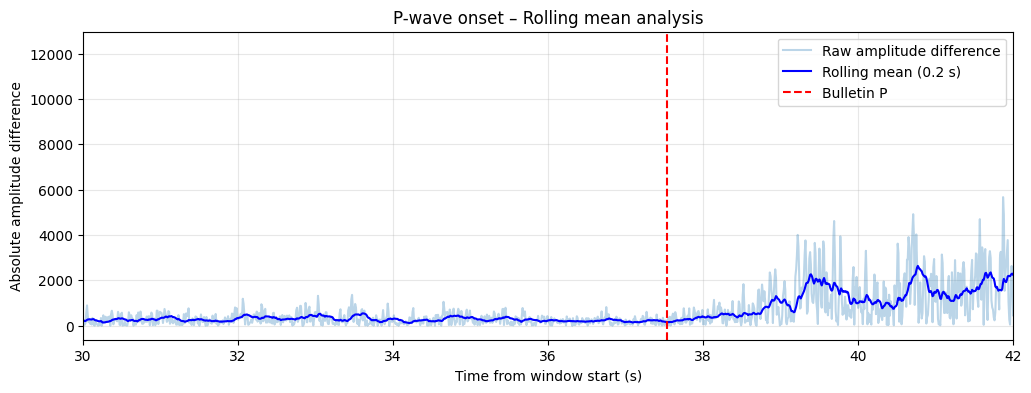

In [24]:

# Smooth amplitude differences using a 0.2-second rolling window

window = int(0.2 * tr_test.stats.sampling_rate)

p_rolling = amplitude_diff_test.rolling(
    window=window,
    min_periods=window
).mean()

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_diff_test,
         alpha=0.3, label="Raw amplitude difference")

plt.plot(time_test / 1000, p_rolling,
         color="blue", linewidth=1.5,
         label="Rolling mean (0.2 s)")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(30, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("Absolute amplitude difference")
plt.title("P-wave onset – Rolling mean analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


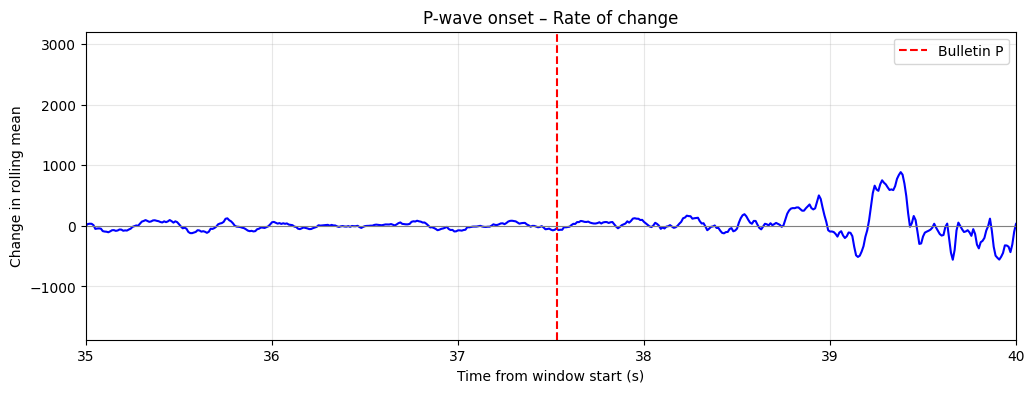

In [25]:

# Rate of change in the rolling mean

p_change = p_rolling.diff(periods=10)

plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, p_change, color="blue")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.axhline(0, color="gray", linewidth=0.8)

plt.xlim(35, 40)
plt.xlabel("Time from window start (s)")
plt.ylabel("Change in rolling mean")
plt.title("P-wave onset – Rate of change")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


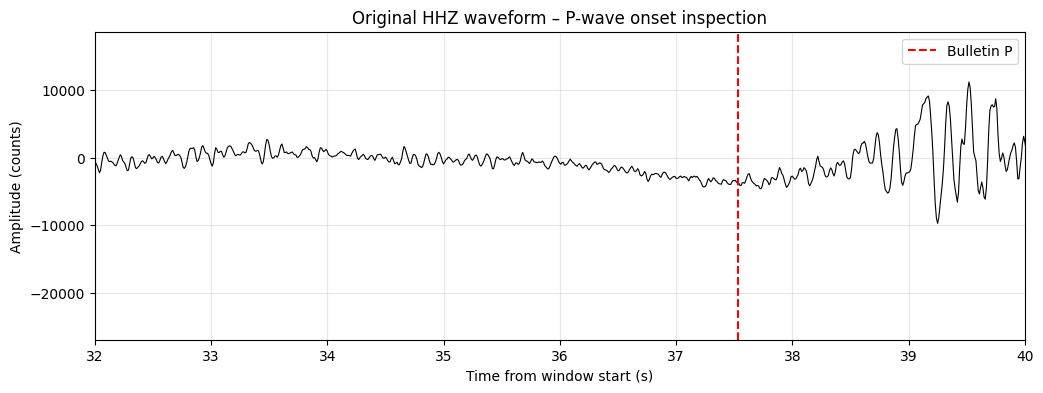

In [26]:

# Inspect the original HHZ waveform around the P arrival

plt.figure(figsize=(12, 4))

plt.plot(time_test / 1000, amplitude_test, color="black", lw=0.8)

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(32, 40)
plt.xlabel("Time from window start (s)")
plt.ylabel("Amplitude (counts)")
plt.title("Original HHZ waveform – P-wave onset inspection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


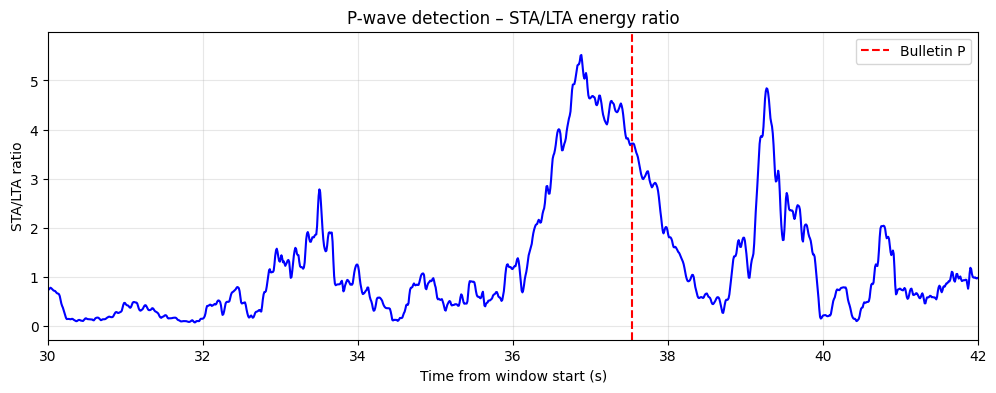

In [27]:

# P-wave detection using STA/LTA on HHZ

fs = tr_test.stats.sampling_rate
energy_p = amplitude_test ** 2

sta_p = energy_p.rolling(
    window=int(0.2 * fs),
    min_periods=int(0.2 * fs)
).mean()

lta_p = energy_p.rolling(
    window=int(3.0 * fs),
    min_periods=int(3.0 * fs)
).mean()

ratio_p = sta_p / (lta_p + 1e-12)

plt.figure(figsize=(12, 4))
plt.plot(time_test / 1000, ratio_p, color="blue")

plt.axvline(37.53, color="red",
            linestyle="--", label="Bulletin P")

plt.xlim(30, 42)
plt.xlabel("Time from window start (s)")
plt.ylabel("STA/LTA ratio")
plt.title("P-wave detection – STA/LTA energy ratio")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


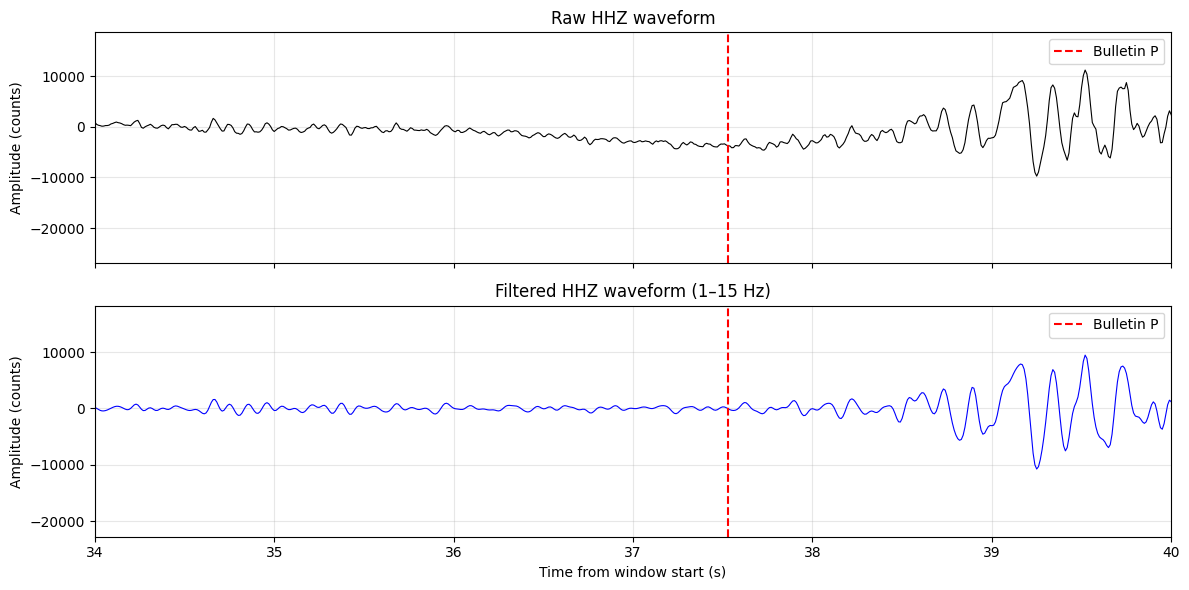

In [28]:

# Compare raw and filtered HHZ waveforms

tr_filtered_test = tr_test.copy()
tr_filtered_test.detrend("demean")
tr_filtered_test.filter(
    "bandpass", freqmin=1, freqmax=15,
    corners=4, zerophase=True
)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(time_test / 1000, tr_test.data, color="black", lw=0.8)
axes[0].set_title("Raw HHZ waveform")

axes[1].plot(time_test / 1000, tr_filtered_test.data, color="blue", lw=0.8)
axes[1].set_title("Filtered HHZ waveform (1–15 Hz)")

for ax in axes:
    ax.axvline(37.53, color="red", linestyle="--", label="Bulletin P")
    ax.set_ylabel("Amplitude (counts)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[1].set_xlim(34, 40)
axes[1].set_xlabel("Time from window start (s)")

plt.tight_layout()
plt.show()


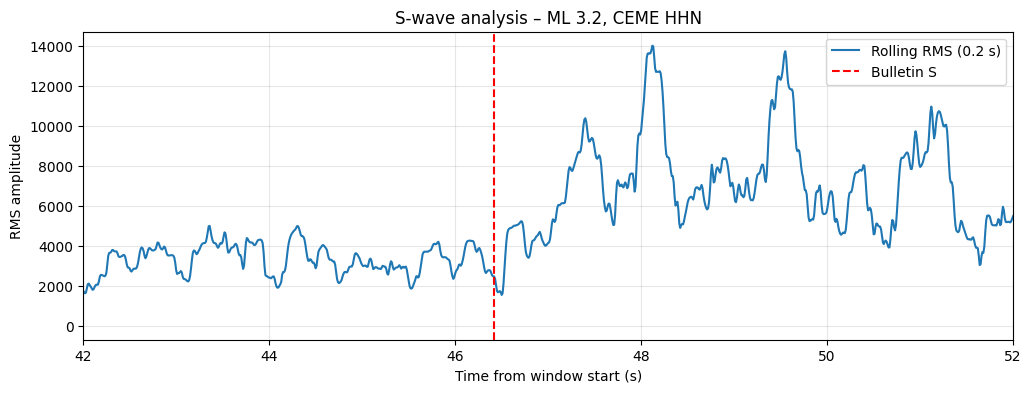

In [29]:

# S-wave analysis – ML 3.2, CEME HHN

tr_s_test = st_test.select(channel="HHN")[0].copy()

fs = tr_s_test.stats.sampling_rate
time_s = tr_s_test.times() * 1000

hhn_test = pd.Series(tr_s_test.data.astype(float))

# Rolling RMS (0.2 s)
window = int(0.2 * fs)

s_rms_test = np.sqrt(
    (hhn_test ** 2).rolling(
        window=window, min_periods=window
    ).mean()
)

# RMS change over 0.1 s
lag = int(0.1 * fs)

s_change_test = s_rms_test.diff(periods=lag)

s_smooth_test = s_change_test.rolling(
    window=lag, min_periods=lag
).mean()

# Visual inspection
plt.figure(figsize=(12, 4))

plt.plot(time_s / 1000, s_rms_test,
         label="Rolling RMS (0.2 s)")

plt.axvline(46.42, color="red",
            linestyle="--", label="Bulletin S")

plt.xlim(42, 52)
plt.xlabel("Time from window start (s)")
plt.ylabel("RMS amplitude")
plt.title("S-wave analysis – ML 3.2, CEME HHN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [30]:

# Find the strongest RMS increase

search_mask = (time_s >= 45000) & (time_s <= 48000)

valid_indices = np.where(
    search_mask & np.isfinite(s_smooth_test.to_numpy())
)[0]

s_index_test = valid_indices[
    np.argmax(s_smooth_test.iloc[valid_indices].to_numpy())
]

# Find the preceding RMS minimum (0.3 s)
lookback = int(0.3 * fs)
start_idx = max(0, s_index_test - lookback)

rms_segment = s_rms_test.iloc[start_idx:s_index_test + 1]
s_onset_index_test = rms_segment.idxmin()

s_onset_ms_test = time_s[s_onset_index_test]
s_onset_utc_test = (
    tr_s_test.stats.starttime + s_onset_ms_test / 1000
)

print("Strongest RMS increase:",
      tr_s_test.stats.starttime + time_s[s_index_test] / 1000)

print("Estimated S onset:", s_onset_utc_test)


Strongest RMS increase: 2024-03-14T03:15:03.050000Z
Estimated S onset: 2024-03-14T03:15:02.920000Z


In [31]:

# Compare detected S arrival with the bulletin

s_bulletin = UTCDateTime("2024-03-14T03:15:02.840")

s_difference = s_onset_utc_test - s_bulletin

print("Bulletin S (UTC):", s_bulletin)
print("Detected S (UTC):", s_onset_utc_test)
print("Difference (seconds):", round(s_difference, 3))
print("Difference (milliseconds):", round(s_difference * 1000))


Bulletin S (UTC): 2024-03-14T03:15:02.840000Z
Detected S (UTC): 2024-03-14T03:15:02.920000Z
Difference (seconds): 0.08
Difference (milliseconds): 80


In [32]:

# Select earthquakes with magnitude between 2.0 and 3.0

candidates = caradje_march[
    caradje_march["magnitude_ML_or_Md"].between(2.0, 3.0)
]

display(candidates.head(10))


,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg,distance_km,origin_datetime
284,2024,3,14,3,19,24.97,0.24,42.9538,0.0033,18.6537,0.0068,19.1,1.0,2.2,34,153,2.323354,2024-03-14 03:19:24.970000+00:00
403,2024,3,14,3,19,25.69,0.17,42.9829,0.0036,18.6826,0.0066,13.6,1.3,2.2,20,165,2.016703,2024-03-14 03:19:25.690000+00:00
404,2024,3,14,3,20,37.44,0.54,42.9315,0.0080,18.6552,0.0166,17.6,2.0,2.3,32,144,4.749300,2024-03-14 03:20:37.440000+00:00
405,2024,3,14,3,23,3.05,0.15,42.9697,0.0031,18.6611,0.0067,5.3,2.7,2.2,18,165,0.478207,2024-03-14 03:23:03.050000+00:00
406,2024,3,14,3,25,4.49,0.20,42.9650,0.0037,18.6383,0.0079,11.2,1.3,2.4,22,171,2.100646,2024-03-14 03:25:04.490000+00:00
407,2024,3,14,3,26,14.81,0.33,42.9326,0.0070,18.6894,0.0099,9.0,2.5,2.0,32,158,5.151131,2024-03-14 03:26:14.810000+00:00
408,2024,3,14,3,29,34.49,0.23,43.0191,0.0042,18.6823,0.0063,10.0,11.1,2.4,27,171,5.305648,2024-03-14 03:29:34.490000+00:00
409,2024,3,14,3,29,59.32,0.07,43.0317,0.0034,18.6394,0.0043,10.0,11.1,2.2,14,295,6.652040,2024-03-14 03:29:59.320000+00:00
410,2024,3,14,3,35,2.23,0.19,42.9421,0.0048,18.6748,0.0064,11.6,1.3,2.3,30,166,3.720648,2024-03-14 03:35:02.230000+00:00
411,2024,3,14,3,36,32.19,0.11,42.9312,0.0023,18.6774,0.0043,9.0,1.0,2.0,22,138,4.942765,2024-03-14 03:36:32.190000+00:00


### 3th TEST, EQ ML 2,3 od 14.03.2024. u 03:20:37.440 UTC
Selected event have low guality for furder testing

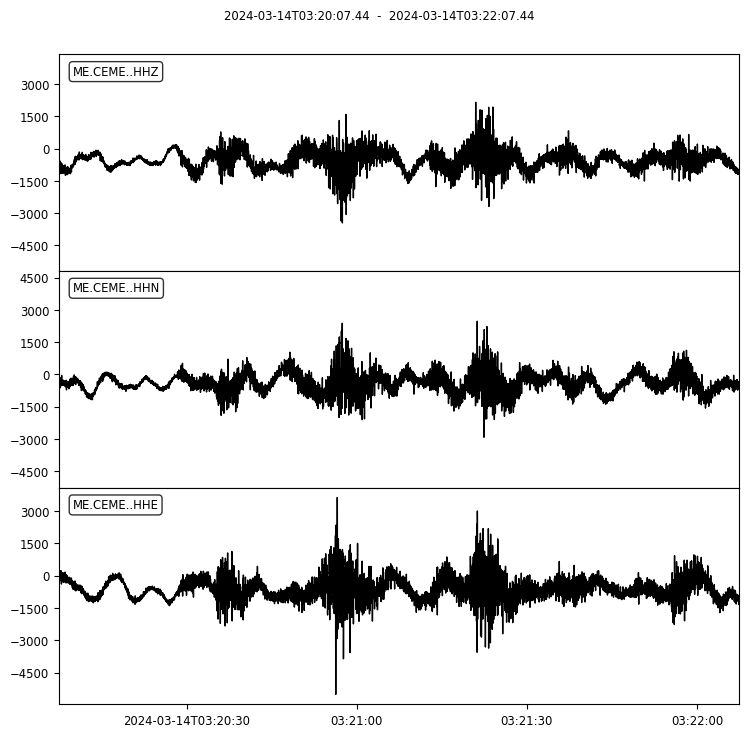

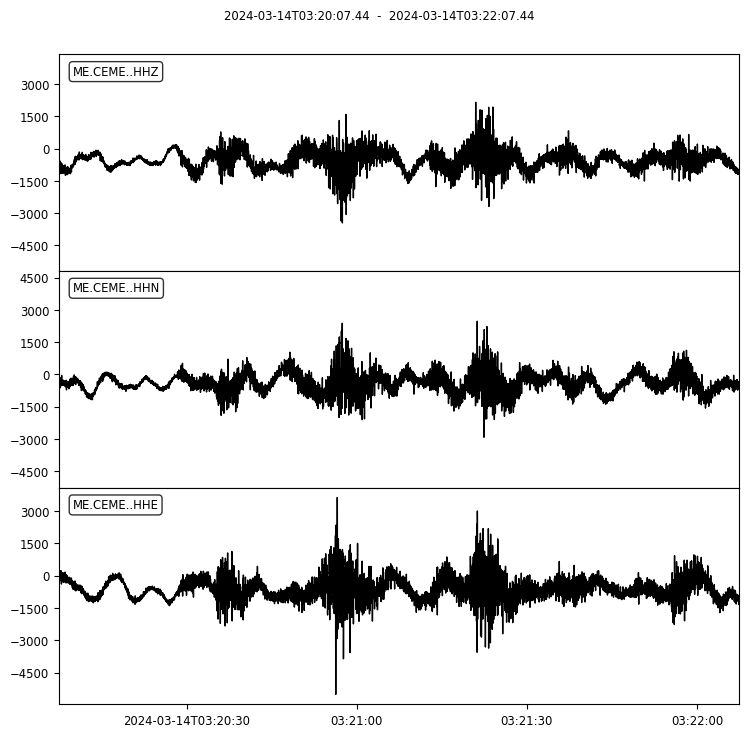

In [33]:

# Third test event: ML 2.3

t0_test3 = UTCDateTime("2024-03-14T03:20:37.440")

st_test3 = st.slice(
    starttime=t0_test3 - 30,
    endtime=t0_test3 + 90
).copy()

st_test3.plot()


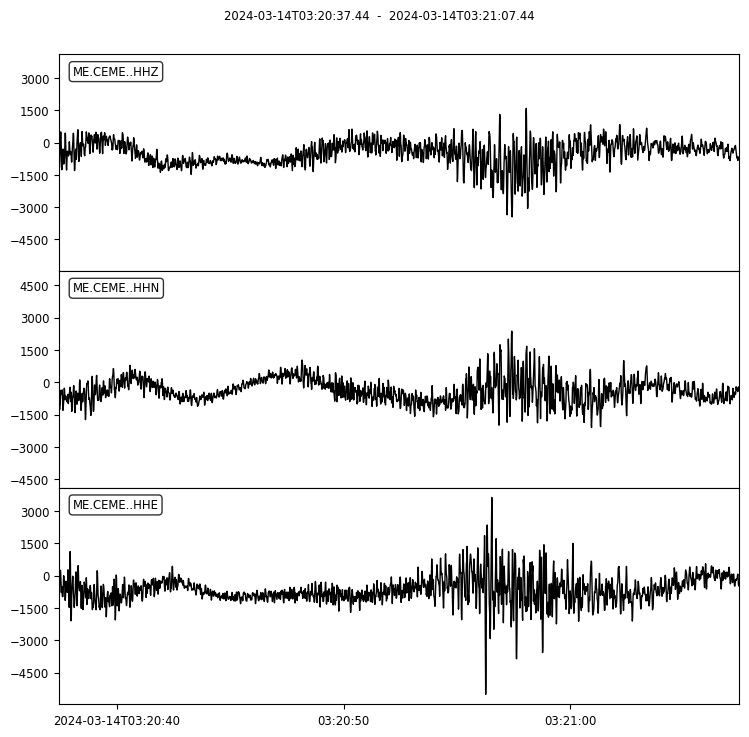

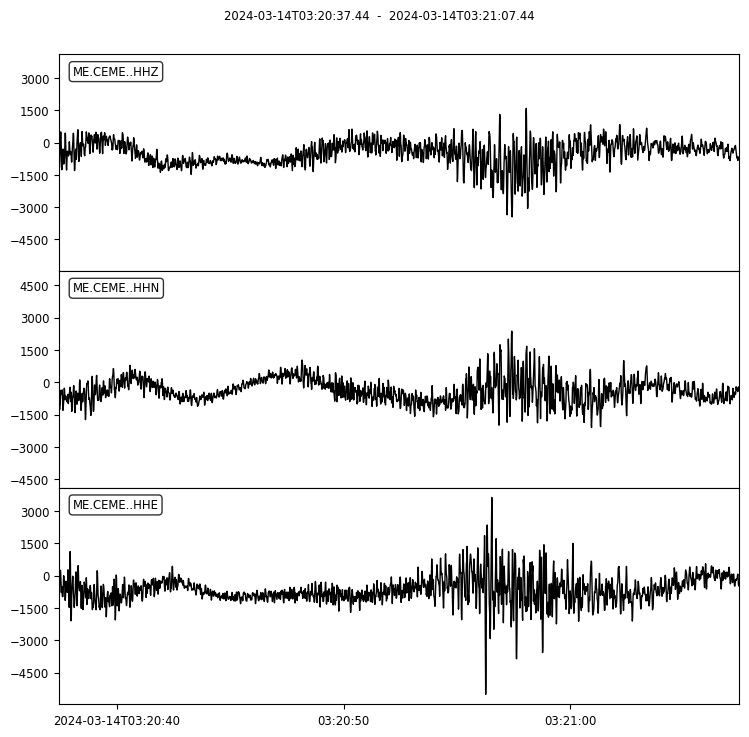

In [34]:

# Zoom in around the third event

st_test3.slice(
    starttime=t0_test3,
    endtime=t0_test3 + 30
).plot()


### 4th TEST, EQ ML 2,3 od 14.03.2024. u 03:20:37.440 UTC

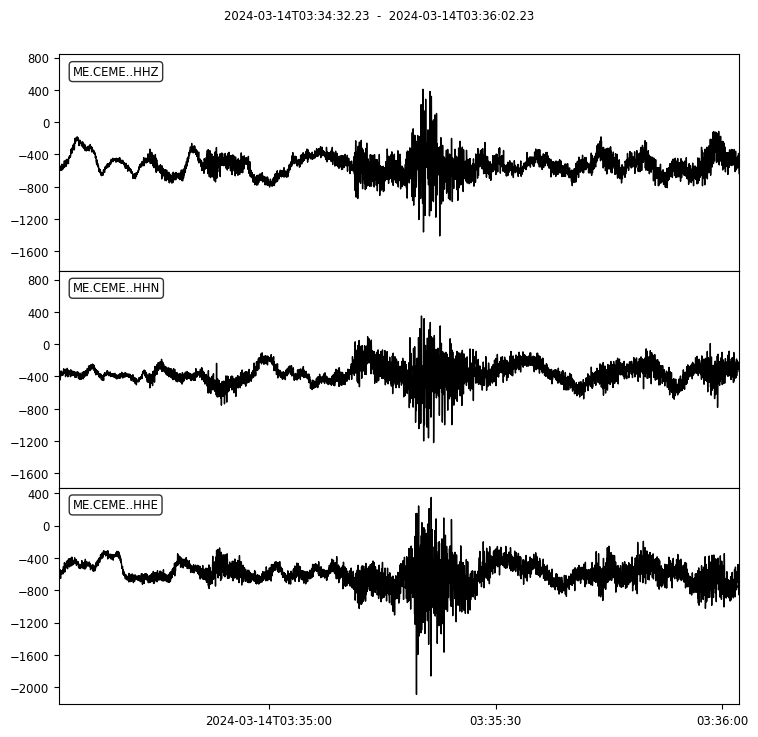

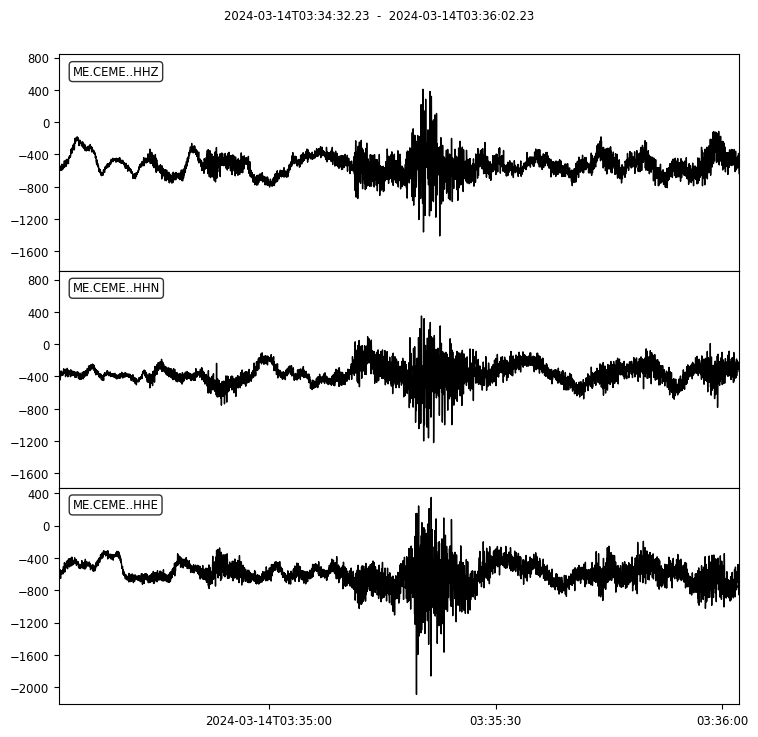

In [35]:

# nTest event: ML 2.3

t0_test4 = UTCDateTime("2024-03-14T03:35:02.230")

st_test4 = st.slice(
    starttime=t0_test4 - 30,
    endtime=t0_test4 + 60
).copy()

st_test4.plot()


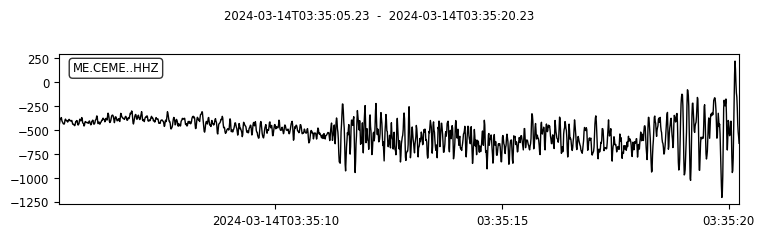

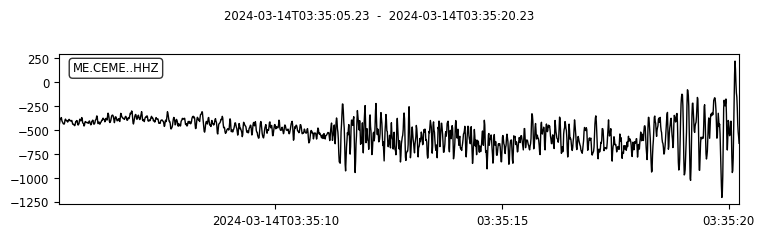

In [36]:

# Zoom in on the P-wave window

tr_p4 = st_test4.select(channel="HHZ")[0]

tr_p4.slice(
    starttime=t0_test4 + 3,
    endtime=t0_test4 + 18
).plot()


In [37]:

# Prepare P-wave detection for the third event

time_p4 = tr_p4.times() * 1000
amplitude_p4 = pd.Series(tr_p4.data.astype(float))

diff_p4 = amplitude_p4.diff().abs().fillna(0)

# Noise window: 33–38 seconds
noise_p4 = diff_p4[(time_p4 >= 33000) & (time_p4 < 38000)]

median_p4 = noise_p4.median()
mad_p4 = (noise_p4 - median_p4).abs().median()

threshold_p4 = median_p4 + 6 * 1.4826 * mad_p4

print("P threshold:", threshold_p4)


P threshold: 84.1648


In [38]:

# Detect P arrival

p_mask4 = (
    (time_p4 >= 35000) &
    (time_p4 <= 48000) &
    (diff_p4 > threshold_p4)
)

p_indices4 = np.where(p_mask4)[0]

if len(p_indices4) > 0:
    p_time_ms4 = time_p4[p_indices4[0]]
    p_arrival_utc4 = tr_p4.stats.starttime + p_time_ms4 / 1000
    print("Detected P arrival (UTC):", p_arrival_utc4)
else:
    print("No P arrival detected")


Detected P arrival (UTC): 2024-03-14T03:35:09.290000Z


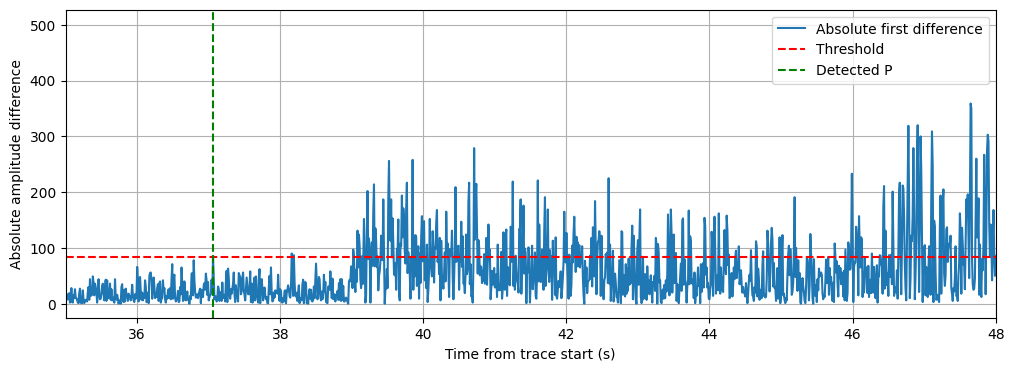

In [39]:

# Plot P detection and threshold

plt.figure(figsize=(12, 4))
plt.plot(time_p4 / 1000, diff_p4, label="Absolute first difference")
plt.axhline(threshold_p4, color="red", linestyle="--", label="Threshold")
plt.axvline(p_time_ms4 / 1000, color="green", linestyle="--", label="Detected P")
plt.xlim(35, 48)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Absolute amplitude difference")
plt.legend()
plt.grid()
plt.show()


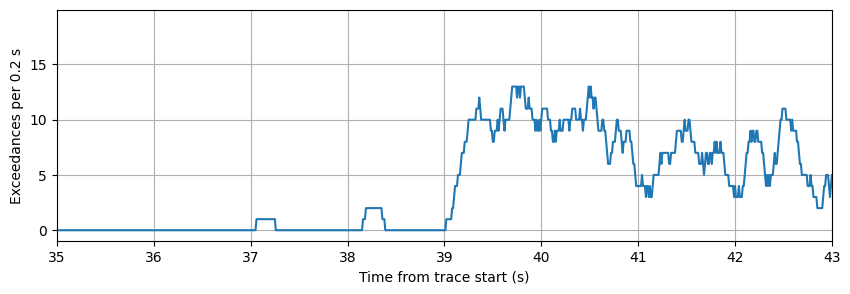

In [40]:

# Count threshold exceedances in 0.2-second windows

exceed_p4 = (diff_p4 > threshold_p4).astype(int)
exceed_count_p4 = exceed_p4.rolling(window=20).sum()

plt.figure(figsize=(10, 3))
plt.plot(time_p4 / 1000, exceed_count_p4)
plt.xlim(35, 43)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Exceedances per 0.2 s")
plt.grid()
plt.show()


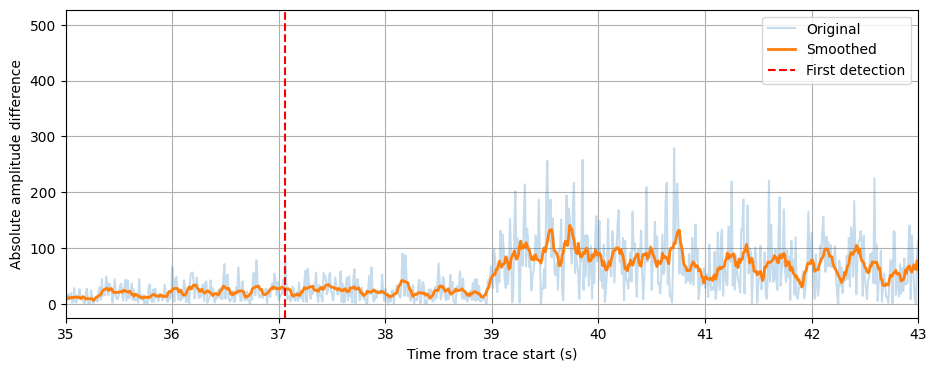

In [41]:

# Smooth absolute first differences (0.1 s)

smooth_p4 = diff_p4.rolling(window=10, center=True).mean()

plt.figure(figsize=(11, 4))
plt.plot(time_p4 / 1000, diff_p4, alpha=0.25, label="Original")
plt.plot(time_p4 / 1000, smooth_p4, linewidth=2, label="Smoothed")
plt.axvline(p_time_ms4 / 1000, color="red", linestyle="--", label="First detection")
plt.xlim(35, 43)
plt.xlabel("Time from trace start (s)")
plt.ylabel("Absolute amplitude difference")
plt.legend()
plt.grid()
plt.show()


In [42]:
p_bulletin_utc4 = ""  # Vrijeme P dolaska na CEME iz biltena, u UTC

if p_indices4.size == 0:
    print("Za četvrti događaj nema P kandidata.")
elif not p_bulletin_utc4:
    print(f"Detektovani P (UTC): {p_arrival_utc4}")
    print("Unesi vrijeme P dolaska iz biltena za CEME.")
else:
    p_reference_utc4 = UTCDateTime(p_bulletin_utc4)
    p_error_s4 = p_arrival_utc4 - p_reference_utc4
    print(f"Detektovani P (UTC): {p_arrival_utc4}")
    print(f"P iz biltena (UTC):  {p_reference_utc4}")
    print(f"Odstupanje: {p_error_s4:+.3f} s")

Detektovani P (UTC): 2024-03-14T03:35:09.290000Z
Unesi vrijeme P dolaska iz biltena za CEME.


In [ ]:

# Install SeisBench
!pip -q install seisbench

# Import SeisBench
import seisbench.models as sbm

# Load the pretrained EQTransformer model
model = sbm.EQTransformer.from_pretrained("original")

print(model)


In [ ]:

# Run EQTransformer on the mainshock waveform segment
result = model.classify(st_event.copy())

# Display earthquake detections
print("Detections:")
print(result.detections)

# Display P and S phase picks
print("\nP and S picks:")
print(result.picks)


In [ ]:

from obspy import UTCDateTime

# Select a 30-minute waveform segment
start = UTCDateTime("2024-03-14T03:00:00")
end = UTCDateTime("2024-03-14T03:30:00")

st_30min = st.copy().trim(starttime=start, endtime=end)

# Run EQTransformer
result_30min = model.classify(st_30min)

# Display detection and phase-picking results
print("Detections:", len(result_30min.detections))
print(result_30min.detections)

print("\nP and S picks:", len(result_30min.picks))
print(result_30min.picks)


In [ ]:

# Display all detected earthquake candidates
print("ALL DETECTIONS")

for i, detection in enumerate(result_30min.detections, start=1):
    print(i, detection)

# Display all P and S phase picks
print("\nALL PHASE PICKS")

for i, pick in enumerate(result_30min.picks, start=1):
    print(i, pick)


In [ ]:

import pandas as pd

# Display all EQTransformer detections
print("EQTransformer detections - CEME")

for i, detection in enumerate(result_30min.detections, start=1):
    print(i, detection)

# Display all P and S picks
print("\nEQTransformer P and S picks")

for i, pick in enumerate(result_30min.picks, start=1):
    print(i, pick)

# Select catalogue earthquakes in the same time interval
catalog_30min = caradje_march[
    (caradje_march["origin_datetime"] >= "2024-03-14 03:00:00") &
    (caradje_march["origin_datetime"] < "2024-03-14 03:30:00")
].copy()

# Display catalogue earthquakes
print("\nCatalogue earthquakes:", len(catalog_30min))

display(
    catalog_30min[
        ["origin_datetime", "magnitude_ML_or_Md",
         "latitude_deg", "longitude_deg", "depth_km"]
    ]
)


In [ ]:
from obspy.geodetics import gps2dist_azimuth

ceme_latitude, ceme_longitude = 42.5467, 18.9177

ceme_catalog = catalog_30min[
    ["origin_datetime", "latitude_deg", "longitude_deg", "depth_km"]
].copy()

ceme_catalog["epicentral_distance_km"] = [
    gps2dist_azimuth(lat, lon, ceme_latitude, ceme_longitude)[0] / 1000
    for lat, lon in zip(ceme_catalog["latitude_deg"], ceme_catalog["longitude_deg"])
]

display(ceme_catalog.round({"epicentral_distance_km": 2}))

In [ ]:
# Import tools for distance calculations and table display.
from math import hypot
import pandas as pd

# Select catalogue event 414 and read its origin time in UTC.
event = ceme_catalog.loc[414]
origin = pd.to_datetime(event["origin_datetime"], utc=True)

# Set the CEME station elevation in kilometers.
station_elevation_km = 0.802

# Estimate the straight-line path from the hypocenter to CEME.
# This calculation assumes the catalogue depth is relative to sea level.
path_km = hypot(
    event["epicentral_distance_km"],
    event["depth_km"] + station_elevation_km,
)

# List each phase with its CG-506 first-layer velocity and EQTransformer pick time.
phases = [
    ("P", 6.03, "2024-03-14T03:06:55.450Z"),
    ("S", 3.26, "2024-03-14T03:07:03.580Z"),
]

# Create an empty list for the results.
rows = []

# Compare predicted and observed arrivals for each phase.
for phase, velocity_km_s, pick_time in phases:
    # Divide the path length by the phase velocity to get travel time.
    travel_time_s = path_km / velocity_km_s

    # Add travel time to the event origin time to predict the arrival.
    predicted_arrival = origin + pd.to_timedelta(travel_time_s, unit="s")

    # Convert the EQTransformer pick time to a UTC timestamp.
    observed_pick = pd.to_datetime(pick_time, utc=True)

    # Subtract the predicted arrival from the observed pick, in seconds.
    residual_s = (observed_pick - predicted_arrival).total_seconds()

    # Save one row of results for this phase.
    rows.append({
        "phase": phase,
        "travel_time_s": travel_time_s,
        "predicted_arrival_utc": predicted_arrival.round("ms"),
        "observed_pick_utc": observed_pick,
        "residual_s": residual_s,
    })

# Display the P and S results with times and residuals rounded for readability.
display(pd.DataFrame(rows).round({"travel_time_s": 3, "residual_s": 3}))

In [ ]:
# Set the CEME station elevation in kilometers.
station_elevation_km = 0.802

# Set the CG-506 first-layer velocities and the CEME pick times.
phases = [
    ("P", 6.03, "2024-03-14T03:19:35.000Z"),
    ("S", 3.26, "2024-03-14T03:19:42.450Z"),
]

# Create an empty list for the comparison results.
comparison_rows = []

# Compare both catalogue events with the same pair of picks.
for event_id in [284, 403]:
    # Read the catalogue row and its origin time in UTC.
    event = ceme_catalog.loc[event_id]
    origin = pd.to_datetime(event["origin_datetime"], utc=True)

    # Estimate the direct path, assuming depth is relative to sea level.
    path_km = hypot(
        event["epicentral_distance_km"],
        event["depth_km"] + station_elevation_km,
    )

    # Predict the arrival and calculate the residual for each phase.
    for phase, velocity_km_s, pick_time in phases:
        travel_time_s = path_km / velocity_km_s
        predicted_arrival = origin + pd.to_timedelta(travel_time_s, unit="s")
        observed_pick = pd.to_datetime(pick_time, utc=True)
        residual_s = (observed_pick - predicted_arrival).total_seconds()

        # Save one row for this event and phase.
        comparison_rows.append({
            "event_id": event_id,
            "phase": phase,
            "predicted_arrival_utc": predicted_arrival.round("ms"),
            "observed_pick_utc": observed_pick,
            "residual_s": residual_s,
        })

# Display the P and S comparisons for both events.
display(pd.DataFrame(comparison_rows).round({"residual_s": 3}))